# 03 — Dense 3D Point Tracking via DELTAv2 & MediaPipe Silhouette Sampling

This notebook demonstrates the **Dense 3D Point Tracking Stage** powered by **DELTAv2** (`DenseTrack3DV2` + `UniDepthV2`) coupled with **MediaPipe Pose Silhouette Masking**.

### Why Dense Silhouette-Guided 3D Tracking?
1. **Failure of Sparse 3-Point Tracking**: Tracking only 3 isolated points fails when loose clothing wrinkles or when the swinging contralateral leg briefly occludes the stance thigh.
2. **Failure of Unmasked Bounding-Box Grids**: Sampling a rectangular grid around the body feeds ~60% static background wall/floor pixels into the transformer's local correlation attention, dragging limb trajectories toward the static background (*background drag*).
3. **Our Solution — Anatomical Silhouette Sampling (`DeltaV2Tracker`)**:
   - **3 Anatomical Anchor Points** ($P_1, P_2, P_3$) + **200 Dense Thigh Points** sampled strictly inside the femoral quadrilateral (`Total = 203 thigh points`, indices `0..202`).
   - **~780–800 Contextual Full-Body Silhouette Points** constrained via MediaPipe segmentation mask to capture global human translation without background contamination.
   - **Bidirectional Coarse-to-Fine 3D Tracking**: Tracks forward and backward from `ref_frame_idx` using metric depth maps from **UniDepthV2**.

In [1]:
import os
import sys
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "examples" else current_dir
os.chdir(str(project_root))
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

plt.rcParams["figure.dpi"] = 110
print(f"Workspace initialized: {project_root.name}")

Workspace initialized: monocular-3d-gait-tracking-deltav2


## 1. Inspecting Cached Raw DELTAv2 Trajectory Tensors & Query Distribution

We load the raw tracking tensor `delta_v2_raw_P27_E2T2_90.mp4.npz` and inspect how the $N = 987$ query points are distributed at the reference frame (`ref_frame_idx = 115`):
- **Indices `0..2`**: The 3 anatomical anchor keypoints $(P_1, P_2, P_3)$.
- **Indices `3..202`**: 200 dense points sampled uniformly inside the segmented right thigh mask.
- **Indices `203..986`**: 784 contextual body silhouette points providing global rigid-body context to the transformer.

Video Name          : P27_E2T2_90.mp4 | FPS: 30.0 | Window Start: 0 | Ref Frame: 19 (rel=19)
2D Trajectory Shape : (250, 987, 2) (T=250 frames, N=987 points, 2 pixel coords)
3D Metric Shape     : (250, 987, 3) (T=250 frames, N=987 points, 3 metric XYZ coords in meters)
Mean Visibility     : 84.9% | Mean Confidence: 0.989


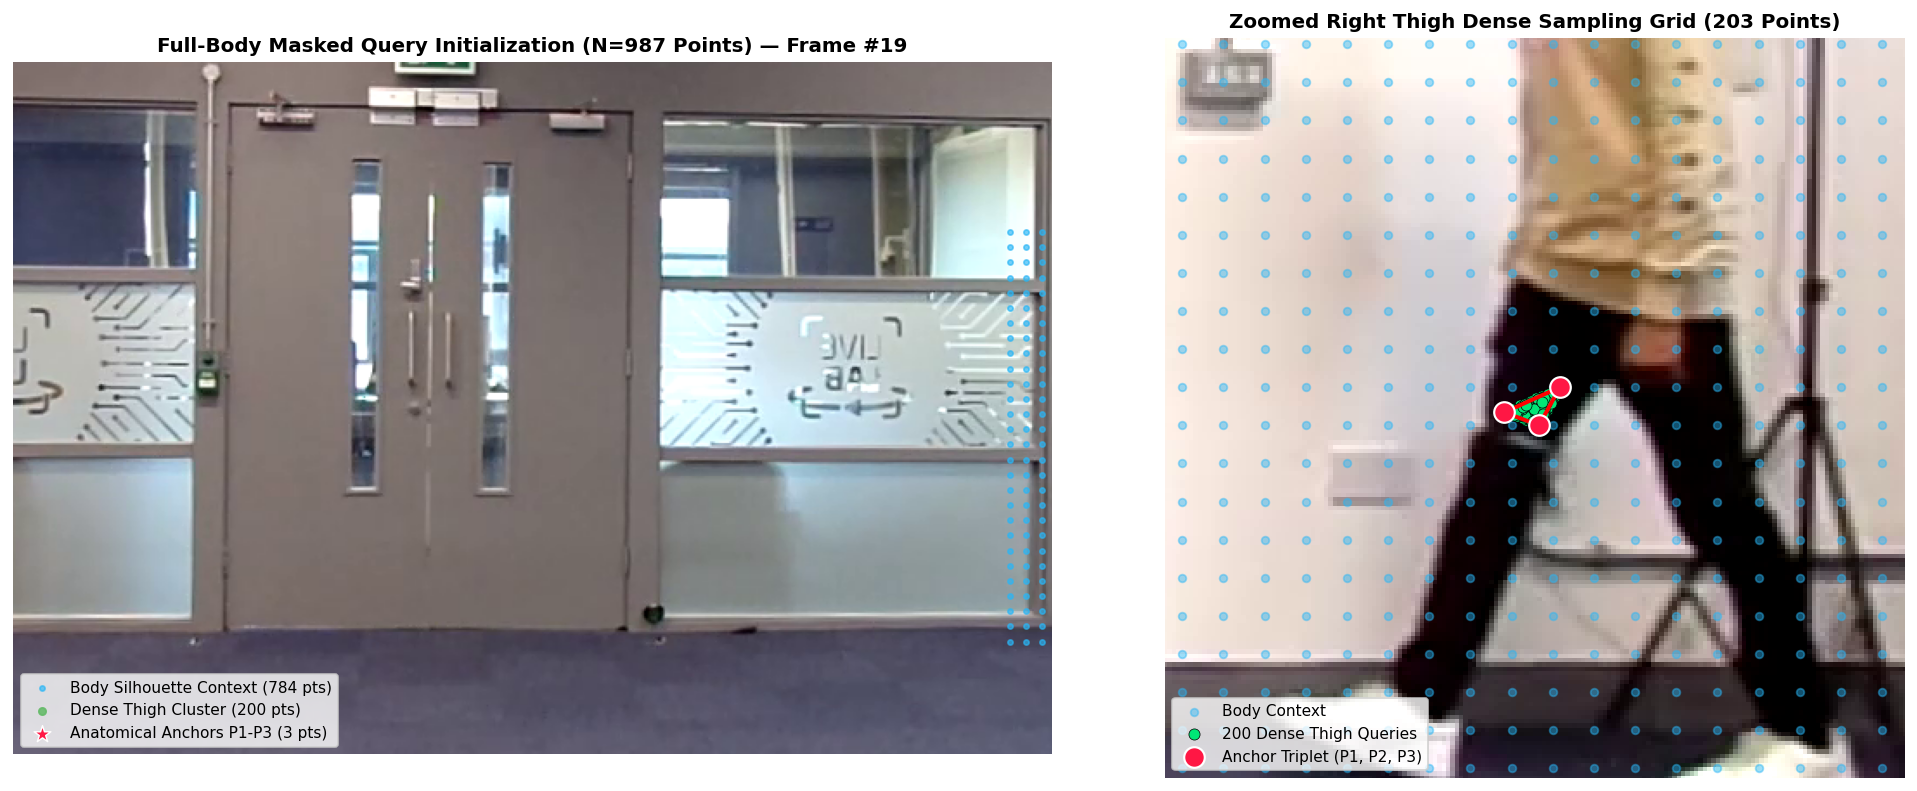

In [2]:
from src.data_io.dataset_scanner import DatasetScanner
from src.data_io.video_reader import video_provider

video_name = "P27_E2T2_90.mp4"
raw_npz_path = project_root / "data" / "inference_results" / "raw" / f"delta_v2_raw_{video_name}.npz"
raw_data = np.load(raw_npz_path, allow_pickle=True)

track2d = raw_data["track2d"]              # (T, N, 2) in model resolution
track3d_world = raw_data["track3d_world"]  # (T, N, 3) in metric 3D camera/world space (meters)
visibility = raw_data["visibility"]        # (T, N) boolean visibility mask
confidence = raw_data["confidence"]        # (T, N) confidence scores
ref_frame_idx = int(raw_data["ref_frame_idx"])
start_idx = int(raw_data["start_idx"])
fps = float(raw_data["fps"])
scales = raw_data["scales"]                # [scale_x, scale_y] from original RGB to model resolution

T, N, _ = track3d_world.shape
rel_ref = ref_frame_idx - start_idx

print(f"Video Name          : {video_name} | FPS: {fps:.1f} | Window Start: {start_idx} | Ref Frame: {ref_frame_idx} (rel={rel_ref})")
print(f"2D Trajectory Shape : {track2d.shape} (T={T} frames, N={N} points, 2 pixel coords)")
print(f"3D Metric Shape     : {track3d_world.shape} (T={T} frames, N={N} points, 3 metric XYZ coords in meters)")
print(f"Mean Visibility     : {np.mean(visibility)*100:.1f}% | Mean Confidence: {np.mean(confidence):.3f}")

# Load RGB reference frame and map 2D query points back to original video resolution
scanner = DatasetScanner(str(project_root / "data"))
v_info = next(v for v in scanner if v.name == video_name)
frame_bgr, _ = video_provider.get_frame(project_root / v_info.video_path, ref_frame_idx)
frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

pts_2d_orig = track2d[rel_ref] / scales  # Map from model space back to 1280x720 RGB pixels
anchor_pts = pts_2d_orig[:3]
thigh_pts = pts_2d_orig[3:203]
body_pts = pts_2d_orig[203:]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.2))
ax1.imshow(frame_rgb)
ax1.scatter(body_pts[:, 0], body_pts[:, 1], c="#29B6F6", s=8, alpha=0.65, label=f"Body Silhouette Context ({len(body_pts)} pts)")
ax1.scatter(thigh_pts[:, 0], thigh_pts[:, 1], c="#66BB6A", s=16, alpha=0.9, label="Dense Thigh Cluster (200 pts)")
ax1.scatter(anchor_pts[:, 0], anchor_pts[:, 1], c="#FF1744", s=95, marker="*", edgecolors="white", lw=0.8, zorder=10, label="Anatomical Anchors P1-P3 (3 pts)")
ax1.set_xlim(350, 950)
ax1.set_ylim(620, 220)
ax1.set_title(f"Full-Body Masked Query Initialization (N={N} Points) — Frame #{ref_frame_idx}", fontsize=11, fontweight="bold")
ax1.legend(loc="lower left", fontsize=8.5)
ax1.axis("off")

ax2.imshow(frame_rgb)
ax2.scatter(body_pts[:, 0], body_pts[:, 1], c="#29B6F6", s=18, alpha=0.45, label="Body Context")
ax2.scatter(thigh_pts[:, 0], thigh_pts[:, 1], c="#00E676", s=38, edgecolors="black", lw=0.4, label="200 Dense Thigh Queries")
tri_closed = np.vstack([anchor_pts, anchor_pts[0]])
ax2.plot(tri_closed[:, 0], tri_closed[:, 1], "r-", lw=2.2, zorder=9)
ax2.scatter(anchor_pts[:, 0], anchor_pts[:, 1], c="#FF1744", s=130, edgecolors="white", lw=1.2, zorder=10, label="Anchor Triplet (P1, P2, P3)")
cx, cy = np.mean(thigh_pts, axis=0)
ax2.set_xlim(cx - 85, cx + 85)
ax2.set_ylim(cy + 85, cy - 85)
ax2.set_title("Zoomed Right Thigh Dense Sampling Grid (203 Points)", fontsize=11, fontweight="bold")
ax2.legend(loc="lower left", fontsize=8.5)
ax2.axis("off")

plt.tight_layout()
plt.show()

## 2. Multi-Frame 2D Tracking Progression Across Key Gait Phases

Below we render the tracked thigh cluster (`indices 0..202`) across 4 distinct phases of the gait sequence, including **contralateral limb crossover** where the swinging left leg passes behind/across the tracked right thigh.

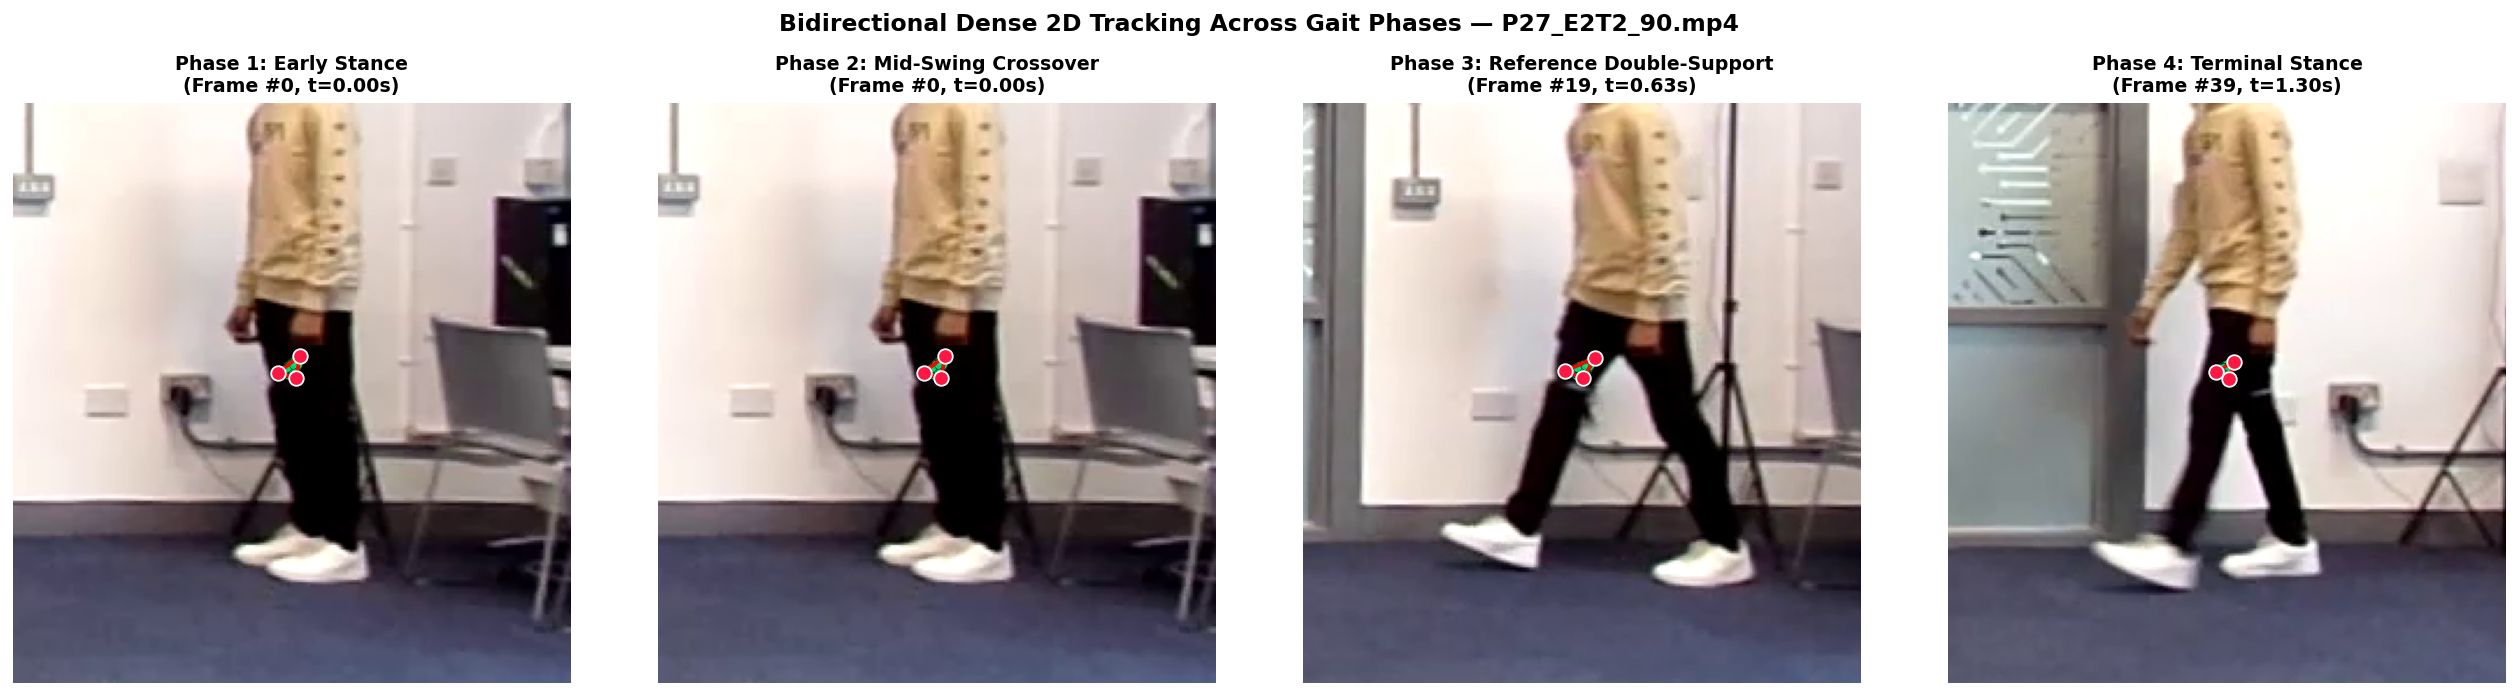

In [3]:
sample_rel_indices = [
    max(0, rel_ref - 45),
    max(0, rel_ref - 20),
    rel_ref,
    min(T - 1, rel_ref + 20),
]
phase_Labels = [
    "Phase 1: Early Stance",
    "Phase 2: Mid-Swing Crossover",
    "Phase 3: Reference Double-Support",
    "Phase 4: Terminal Stance",
]

fig, axes = plt.subplots(1, 4, figsize=(20, 5.2))
for ax, r_idx, p_title in zip(axes, sample_rel_indices, phase_Labels):
    abs_f = start_idx + r_idx
    f_bgr, _ = video_provider.get_frame(project_root / v_info.video_path, abs_f)
    f_rgb = cv2.cvtColor(f_bgr, cv2.COLOR_BGR2RGB)
    pts_t = track2d[r_idx, :203] / scales
    anc_t = pts_t[:3]

    ax.imshow(f_rgb)
    ax.scatter(pts_t[3:, 0], pts_t[3:, 1], c="#00E676", s=18, alpha=0.8, edgecolors="black", lw=0.3)
    t_close = np.vstack([anc_t, anc_t[0]])
    ax.plot(t_close[:, 0], t_close[:, 1], "r-", lw=2.0, zorder=8)
    ax.scatter(anc_t[:, 0], anc_t[:, 1], c="#FF1744", s=65, edgecolors="white", zorder=9)

    mx, my = np.median(pts_t, axis=0)
    ax.set_xlim(mx - 120, mx + 120)
    ax.set_ylim(my + 135, my - 115)
    ax.set_title(f"{p_title}\n(Frame #{abs_f}, t={r_idx/fps:.2f}s)", fontsize=10.5, fontweight="bold")
    ax.axis("off")

fig.suptitle(f"Bidirectional Dense 2D Tracking Across Gait Phases — {video_name}", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 3. Metric 3D Point Cloud & Trajectory Evolution

Using **UniDepthV2**, DELTAv2 unprojects every 2D pixel track into metric 3D camera coordinates $[X(t), Y(t), Z(t)]$ in meters. Below we visualize the 3D point cloud of the thigh vs full body at the reference frame and the 3D centroid displacement over time.

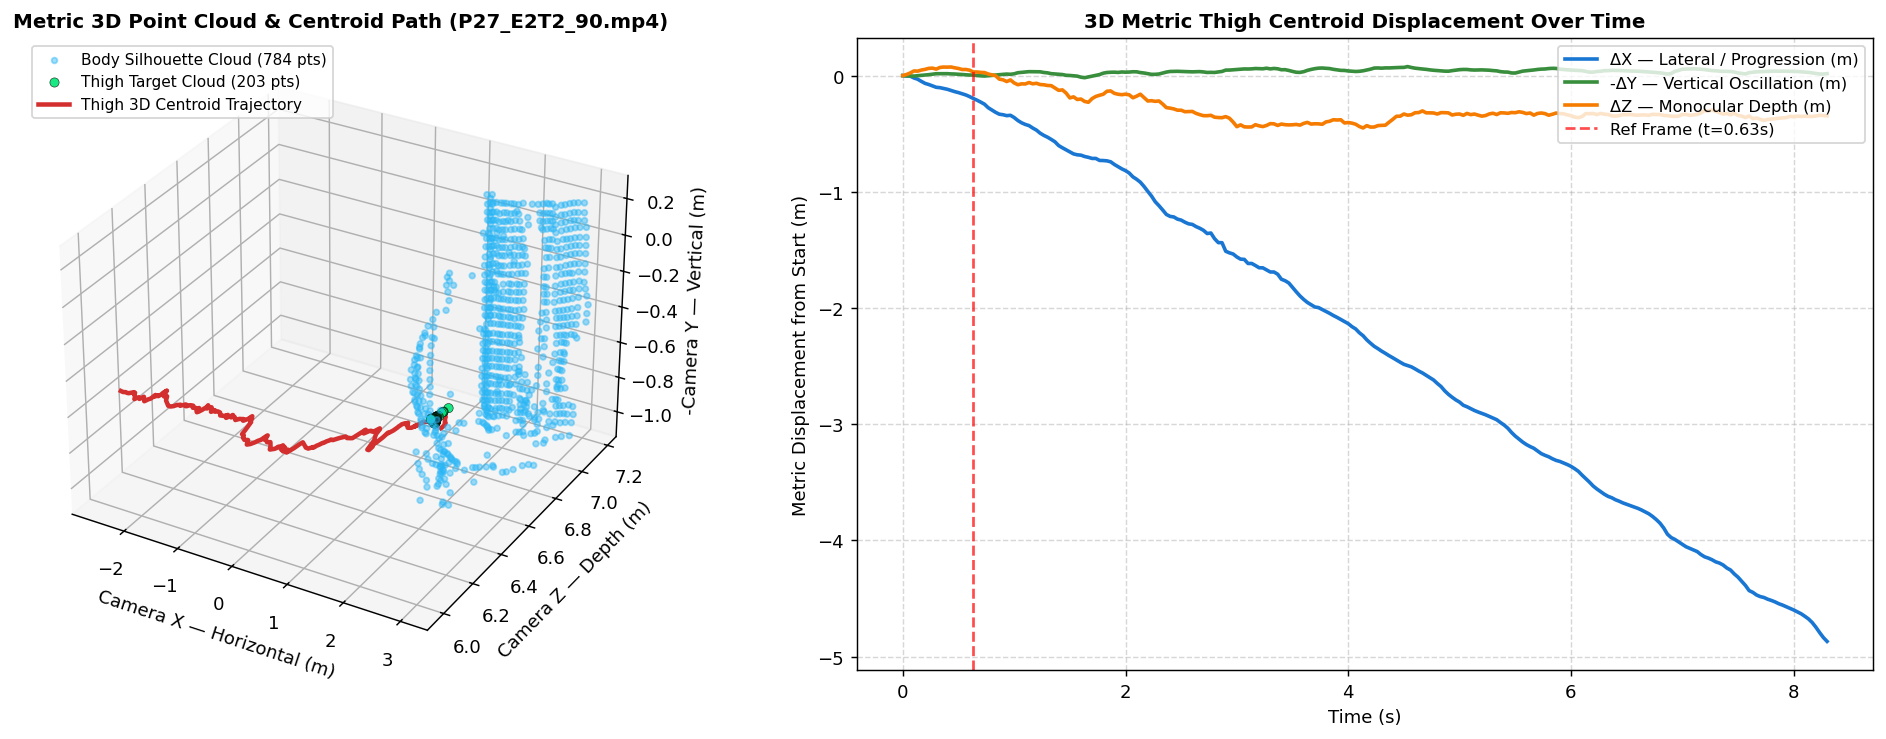

In [4]:
pts3d_ref = track3d_world[rel_ref]
thigh_3d_ref = pts3d_ref[:203]
body_3d_ref = pts3d_ref[203:]

thigh_centroid_3d = np.mean(track3d_world[:, :203, :], axis=1)  # (T, 3)
t_axis = np.arange(T) / fps

fig = plt.figure(figsize=(16, 5.8))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.scatter(body_3d_ref[:, 0], body_3d_ref[:, 2], -body_3d_ref[:, 1], c="#29B6F6", s=10, alpha=0.45, label="Body Silhouette Cloud (784 pts)")
ax1.scatter(thigh_3d_ref[:, 0], thigh_3d_ref[:, 2], -thigh_3d_ref[:, 1], c="#00E676", s=26, edgecolors="black", lw=0.3, alpha=0.9, label="Thigh Target Cloud (203 pts)")
ax1.plot(thigh_centroid_3d[:, 0], thigh_centroid_3d[:, 2], -thigh_centroid_3d[:, 1], color="#D32F2F", lw=2.5, label="Thigh 3D Centroid Trajectory")
ax1.set_title(f"Metric 3D Point Cloud & Centroid Path ({video_name})", fontsize=11, fontweight="bold")
ax1.set_xlabel("Camera X — Horizontal (m)")
ax1.set_ylabel("Camera Z — Depth (m)")
ax1.set_zlabel("-Camera Y — Vertical (m)")
ax1.legend(loc="upper left", fontsize=8.5)

ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(t_axis, thigh_centroid_3d[:, 0] - thigh_centroid_3d[0, 0], label="ΔX — Lateral / Progression (m)", lw=2.0, color="#1976D2")
ax2.plot(t_axis, -(thigh_centroid_3d[:, 1] - thigh_centroid_3d[0, 1]), label="-ΔY — Vertical Oscillation (m)", lw=2.0, color="#388E3C")
ax2.plot(t_axis, thigh_centroid_3d[:, 2] - thigh_centroid_3d[0, 2], label="ΔZ — Monocular Depth (m)", lw=2.0, color="#F57C00")
ax2.axvline(rel_ref / fps, color="red", ls="--", alpha=0.7, label=f"Ref Frame (t={rel_ref/fps:.2f}s)")
ax2.set_title("3D Metric Thigh Centroid Displacement Over Time", fontsize=11, fontweight="bold")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Metric Displacement from Start (m)")
ax2.legend(loc="upper right", fontsize=9)
ax2.grid(True, ls="--", alpha=0.5)

plt.tight_layout()
plt.show()